In [1]:
%cd ..

/Users/maxschmaltz/Documents/DieKonstraintsPrivat/comp_modeling


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict
from itertools import product
import json
from typing import List

from data_utils.load_datasets import load_constraints, load_appl_ind, save_tsv_generic
from comp_modeling.compxconstraints import CompXConstraints, DEF_ID

Load GermaNet data...: 100%|█████████▉| 99.99999999999996/100 [00:12<00:00,  8.03it/s] 
Load Wiktionary data...: 100%|██████████| 100.0/100 [00:00<00:00, 290.17it/s]            
Load Ili records...: 100%|██████████| 100.0/100 [00:00<00:00, 129694.00it/s]


In [3]:
constr_path = "constraints/constraints_all_revised.yaml"

constraints = load_constraints(constr_path)

## Dataset & Constraint Interaction Complexity

Our modeling dataset consists of ~900 compounds (36 unique N1s) with all implemented constraints defined over them. We derived it by intersecting the items of _GeCoDB\_v07\_GN_ and _SP18\_Pl\_Constr_.

In [4]:
appl_ind_path = "resources/developed/merged_geco_sp_appl_ind.tsv"

appl_ind = load_appl_ind(
    appl_ind_path=appl_ind_path,
    # this dataset is clean
    remove_na_columns=False,
    remove_unconfirmed=False,
    remove_missing=False
)

appl_ind.sample(5)

,linker,def-0_is_applicable,def-0_applies,p2l:decl_cl:pl:#0-0|def-0_is_applicable,p2l:decl_cl:pl:#0-0|def-0_applies,p2l:decl_cl:pl:#s-0_is_applicable,p2l:decl_cl:pl:#s-0_applies,p2l:decl_cl:pl:#e-0|def-0_is_applicable,p2l:decl_cl:pl:#e-0|def-0_applies,p2l:decl_cl:pl:#er-0/er|def-0/er_is_applicable,...,p2l:decl_cl:pl:#e_uml-0|pl_interpr-e_uml_is_applicable,p2l:decl_cl:pl:#e_uml-0|pl_interpr-e_uml_applies,p2l:decl_cl:pl:#0_uml-0|pl_interpr-0_uml_is_applicable,p2l:decl_cl:pl:#0_uml-0|pl_interpr-0_uml_applies,p2l:decl_cl:mixed-0/s/en|pl_interpr-en_is_applicable,p2l:decl_cl:mixed-0/s/en|pl_interpr-en_applies,p2l:drv:sfx:sfx-s|pl_interpr-en_is_applicable,p2l:drv:sfx:sfx-s|pl_interpr-en_applies,p2l:phon_fin:weak_F_cons$-0/s/en|pl_interpr-en_is_applicable,p2l:phon_fin:weak_F_cons$-0/s/en|pl_interpr-en_applies
comp_gecodb,,,,,,,,,,,,,,,,,,,,,
schloss_bewohner,_,True,True,False,NaN,False,NaN,False,NaN,True,...,False,NaN,False,NaN,False,NaN,False,NaN,False,NaN
gitarre_+n_part,_+en_,True,False,False,NaN,False,NaN,False,NaN,False,...,False,NaN,False,NaN,False,NaN,False,NaN,False,NaN
hand_rücken,_,True,True,False,NaN,False,NaN,False,NaN,False,...,False,NaN,False,NaN,False,NaN,False,NaN,False,NaN
mutter_+=_treff,_+=_,True,False,False,NaN,False,NaN,False,NaN,False,...,False,NaN,True,True,False,NaN,False,NaN,False,NaN
haus_sklave,_,True,True,False,NaN,False,NaN,False,NaN,True,...,False,NaN,False,NaN,False,NaN,False,NaN,False,NaN


Since Schäfer & Pankratz 2018 targeted nouns that exhibit an alternation between a pluralic and a non-pluralic linker, _SP18\_Pl\_Constr_ (hence, our modeling dataset) mostly contains simplex masculine and neutral nouns, which prevail among compounds that satisfy this condition. This leads to a noticeable limitation of the dataset: phonological and especially derivational constraints are largely underused in it. Thus, only $62\%$ and $20\%$ of these constraints, respectively, enter the modeling of this dataset.

In [5]:
with open("out/acceptable_linkers.json", encoding="utf-8") as i:
    acceptable_linkers_all = json.load(i)

with open("out/unacceptable_linkers.json", encoding="utf-8") as i:
    unacceptable_linkers_all = json.load(i)

In [6]:
used_constrs = set()
for acceptable_linkers in acceptable_linkers_all.values():
    for linker, constrs in acceptable_linkers.items():
        used_constrs.update(constrs)
for unacceptable_linkers in unacceptable_linkers_all.values():
    for linker, constrs in unacceptable_linkers.items():
        used_constrs.update(constrs)

used_constrs = list(used_constrs)

involved_domains_data = defaultdict(lambda: defaultdict(int))
linkers_by_domains_data = defaultdict(lambda: defaultdict(list))
for c_id in used_constrs:
    if c_id.startswith("p2l:") or c_id == "l2p:en|non_par_m" or c_id == DEF_ID:
        key = ("gen", "ours")
    else:
        key = ("restr", "ours")
    domains = constraints[c_id]["domain_type"]
    for domain in domains:
        involved_domains_data[domain][key] += 1
    if key == ("gen", "ours"):
        domains_str = "+".join(sorted(domains))
        constr_acc_linkers = CompXConstraints.esc_batch(constraints[c_id]["acceptable_linkers"])
        for linker in constr_acc_linkers:
            linkers_by_domains_data[linker][(domains_str, "constraints")].append(c_id)
            

involved_domains_df = pd.DataFrame(involved_domains_data).fillna(0).astype(int)
# involved_domains_df.insert(0, "total", involved_domains_df.sum(axis=1))
involved_domains_df = involved_domains_df.T
involved_domains_df.drop("default", inplace=True)

In [7]:
used_constrs_ref = [
    c_id for c_id, constr in constraints.items()
    if constr["measures"] != "NA" and
    constr["measures"]["regularity"]["item"] >= 0.5
]

involved_domains_ref_data = defaultdict(lambda: defaultdict(int))
for c_id in used_constrs_ref:
    if c_id.startswith("p2l:") or c_id == "l2p:en|non_par_m" or c_id == DEF_ID:
        key = ("gen", "reference")
    else:
        key = ("restr", "reference")
    for domain in constraints[c_id]["domain_type"]:
        involved_domains_ref_data[domain][key] += 1

involved_domains_ref_df = pd.DataFrame(involved_domains_ref_data).fillna(0).astype(int)
involved_domains_ref_df = involved_domains_ref_df.T
involved_domains_ref_df.drop("default", inplace=True)

In [8]:
involved_domains_comparison_df = pd.concat((involved_domains_ref_df, involved_domains_df), axis=1)
for key in ["gen", "restr"]:
    involved_domains_comparison_df[(key, "%")] = (100 * (
        involved_domains_comparison_df[(key, "ours")] /
        involved_domains_comparison_df[(key, "reference")]
    )).fillna(100).astype(int)
involved_domains_comparison_df = involved_domains_comparison_df[
    sorted(involved_domains_comparison_df.columns)
]

save_tsv_generic(involved_domains_comparison_df, "out/involved_domains_comparison.tsv")
involved_domains_comparison_df

gen                restr               
                 % ours reference     % ours reference
morphological   80   16        20   100    8         8
derivational    20    2        10   100    7         7
semantic        90   10        11   100    0         0
phonological    62    5         8    85    6         7
lexical        100    0         0   100    1         1

Given that phonological and derivational constraints are the most productive source of _-s-_, this linker is underrepresented in the dataset.

In [9]:
# from main.py
linkers = appl_ind["linker"].tolist()
n = len(linkers)
unique_linkers = np.unique(linkers)
pd.Series({
    l: linkers.count(l) / n
    for l in unique_linkers
}).sort_values(ascending=False).round(3)

_         0.570
_+en_     0.186
_+=er_    0.160
_+e_      0.048
_+=e_     0.015
_+s_      0.015
_+=_      0.007
dtype: float64

Note that the disproportion becomes striking when we consider the actual involvement of these constraints (cf. analogy of lemma vs. token). The "token usage" of the morphological generative constraints at least doubles all the other domain types combined. Semantic constraints are the second most "token-frequent" domain type. Phonology contributes to linker generation slightly, and derivation negligibly little.

This modeling dataset, then, cannot reflect the actual complexity of German nominal compounding, and cannot be used to build the final German compounding model. However, its simplified constraint interaction provide a favorable ground for the first attempts of modeling German compounding. By focusing on a single morphology vs. semantics interaction, we will not be overwhelmed by the diversity and the number of constraint conflicts. We will therefore be able to produce first insights about constraint conflict resolution and work out a direction for future research. The small size of the dataset will allow for more detailed inspection of the results. Finally, a sane presence of the restrictive constraints will let us investigate constraint elimination to a satisfactory extent. Overall, we suppose that our modeling dataset is a great baseline for the initial findings.

In [10]:
active_gen_domains_data = defaultdict(lambda: defaultdict(int))
for constrs in list(acceptable_linkers_all.values()) + list(unacceptable_linkers_all.values()):
    for c_ids in constrs.values():
        for c_id in c_ids:
            if c_id.startswith("p2l:") or c_id == "l2p:en|non_par_m" or c_id == DEF_ID:
                key = "gen"
            else:
                key = "restr"
            for domain in constraints[c_id]["domain_type"]:
                active_gen_domains_data[domain][key] += 1

active_gen_domains_df = pd.DataFrame(active_gen_domains_data).fillna(0).astype(int)
active_gen_domains_df = active_gen_domains_df.T
active_gen_domains_df.drop("default", inplace=True)

save_tsv_generic(active_gen_domains_df, "out/active_gen_domains.tsv")
active_gen_domains_df

,gen,restr
morphological,1847,4180
semantic,529,0
phonological,295,1707
derivational,20,1756
lexical,0,16


## Quantitative Overview of Constraint Conflicts

The absolute majority of the compounds are covered by 2-4 generative constraints, with mean of $2.7$ and mode of $2$.

Not all of these constraints necessarily conflict within one compound. On average, every $\sim 1.5$ constraints potentially applicable to one compound actually generate the same linker. This begs the question whether these constraints cooperate during linker generation and jointly increase the probability of their linker. On the other hand, some constraints may return multiple generations. We will henceforth refer to this case as _multi-linker_ constraints, as opposed to _targeted_ constraints.

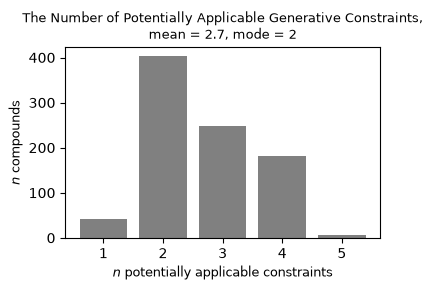

In [11]:
n_constr = [
    len(set([c_id for c_ids in constrs.values() for c_id in c_ids]))
    for constrs in acceptable_linkers_all.values()
]

uc_c = np.unique_counts(n_constr)
x_c = uc_c.values
y_c = uc_c.counts

mean = np.mean(n_constr).round(1)
mode = x_c[y_c.argmax()]

plt.figure(figsize=(4, 3))
plt.bar(x_c, y_c, color="grey")
plt.xlabel(r"$n$ potentially applicable constraints", fontsize=9)
plt.ylabel(r"$n$ compounds", fontsize=9)
plt.title(
    "The Number of Potentially Applicable Generative Constraints,\n"
    f"mean = {mean}, mode = {mode}",
    fontsize=9
)
plt.xticks(x_c)

plt.tight_layout()
plt.savefig("out/n_constrs.png", dpi="figure")
plt.show()

In [12]:
n_accept_linkers = [
    len(accept_linkers)
    for accept_linkers in acceptable_linkers_all.values()
]

(np.array(n_constr) / np.array(n_accept_linkers)).mean().round(1).item()

1.6

In a considerable amount of compounds, the (potentially) cooperating constraints converge to a single generated linker. Still, the constraints generate two linkers for most of the compounds, and even three for some of them (mean, $1.8$, mode $2$).

Remember that these numbers are observed over a modeling dataset with a simplified constraint interaction. The real picture must be more intricate. But again, simplicity is a virtue at this initial attempt to model German compounding: it will be much easier to grasp the first patterns of it from the two-linker outputs.

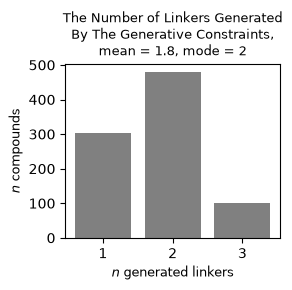

In [13]:
uc_l = np.unique_counts(n_accept_linkers)
x_l = uc_l.values
y_l = uc_l.counts

mean = np.mean(n_accept_linkers).round(1)
mode = x_l[y_l.argmax()]

plt.figure(figsize=(3, 3))
plt.bar(x_l, y_l, color="grey")
plt.xlabel(r"$n$ generated linkers", fontsize=9)
plt.ylabel(r"$n$ compounds", fontsize=9)
plt.title(
    "The Number of Linkers Generated\nBy The Generative Constraints,\n"
    f"mean = {mean}, mode = {mode}",
    fontsize=9
)
plt.xticks(x_l)

plt.tight_layout()
plt.savefig("out/n_generated_linkers.png", dpi="figure")
plt.show()

At the same time, the number of restricted linkers is substantially larger and is 5 or 6 for all the compounds (mean $5.3$, mode $5$).

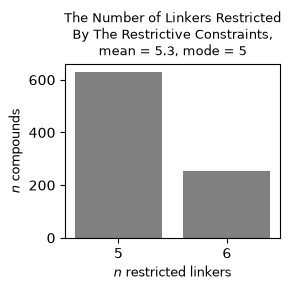

In [14]:
n_unaccept_linkers = [
    len(unaccept_linkers)
    for unaccept_linkers in unacceptable_linkers_all.values()
]

uc_r = np.unique_counts(n_unaccept_linkers)
x_r = uc_r.values
y_r = uc_r.counts

mean = np.mean(n_unaccept_linkers).round(1)
mode = x_r[y_r.argmax()]

plt.figure(figsize=(3, 3))
plt.bar(x_r, y_r, color="grey")
plt.xlabel(r"$n$ restricted linkers", fontsize=9)
plt.ylabel(r"$n$ compounds", fontsize=9)
plt.title(
    "The Number of Linkers Restricted\nBy The Restrictive Constraints,\n"
    f"mean = {mean}, mode = {mode}",
    fontsize=9
)
plt.xticks(x_r)

plt.tight_layout()
plt.savefig("out/n_restricted_linkers.png", dpi="figure")
plt.show()

And still, restrictive linkers may only (potentially!) eliminate a maximum of one linker in a small number of compounds (mean $0.2$, mode $0$).

The explanation to that lies in the fact that most of the restrictive constraints are paradigm-based and eliminate non-paradigmatic linkers. But since most of the linkers can only be generated paradigmatically in the first place, there is virtually almost no need for these conditions. However, the restrictive constraints come largely into handy when what concerns the _-s-_\linker. Our dataset is just unsuitable to test that because, as discussed, the _-s-_ is underrepresented in our data. However, as we will see below, even the small elimination rate we have is helpful in modeling.

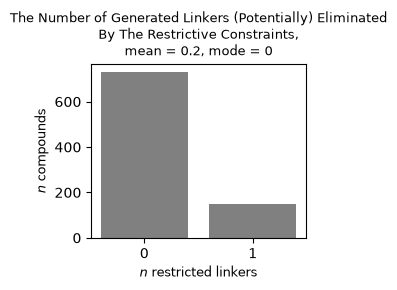

In [15]:
n_eliminated_linkers = [
    len(set(accept_linkers) & set(unaccept_linkers))
    for accept_linkers, unaccept_linkers in zip(
        acceptable_linkers_all.values(), unacceptable_linkers_all.values()
    )
]

uc_e = np.unique_counts(n_eliminated_linkers)
x_e = uc_e.values
y_e = uc_e.counts

mean = np.mean(n_eliminated_linkers).round(1)
mode = x_e[y_e.argmax()]

plt.figure(figsize=(3, 3))
plt.bar(x_e, y_e, color="grey")
plt.xlabel(r"$n$ restricted linkers", fontsize=9)
plt.ylabel(r"$n$ compounds", fontsize=9)
plt.title(
    "The Number of Generated Linkers (Potentially) Eliminated\nBy The Restrictive Constraints,\n"
    f"mean = {mean}, mode = {mode}",
    fontsize=9
)
plt.xticks(x_e)

plt.tight_layout()
plt.savefig("out/n_eliminated_linkers.png", dpi="figure")
plt.show()

## On The Paradox of Semantic Constraints

Pluralic linkers _-e-_, _-"e-_, and _-"0-_ are only ever produced by targeted semantics-involving constraints. Linker _-"er-_ is produced by two targeted semantics-involving constraint and one multi-linker non-semantic constraint. Linker _-en-_ is produced by one targeted semantics-involving constraint, one targeted non-semantic constraints, and two multi-linker non-semantic constraints. In sum, four out of five pluralic linkers are only produced by semantic constraints if we ignore multi-linker constraints. If we include multi-linker constraints back into account, three pluralic linkers are still only produced by semantic constraints. In other words, if we exclude semantics-involving constraints from consideration, we will realistically only be able to produce _-0-_, _-s-_, _-en-_, and maybe _-"er-_.* Indeed, in a dedicated substudy, we predicted the linkers for the entries of the _GeCoDB\_v07\_GN_ dataset, for which the semantic constraints are undefined, using the Albright & Hayes 2002 method. From ~49k trials, only _-0-_, _-s-_, and _-en-_ were ever produced.

This poses a paradox and a modeling challenge for nominal compounding. While the semantic constraints are much less regular, and semantics seems to be only a soft cue in German compounding, it is responsible for at least half of the linker inventory. While the number of the affected compounds is relatively small, it is non-negligible and, and these compounds cannot be conveniently accomodated as exceptions.

In [16]:
linkers_by_domains_df = pd.DataFrame(linkers_by_domains_data)
linkers_by_domains_df.drop(("default", "constraints"), inplace=True)
linkers_by_domains_df = linkers_by_domains_df.T
keys = sorted(linkers_by_domains_df.columns.levels[0], key=lambda x: ("morph" in x), reverse=True)
keys.remove("morphological")
keys.remove("morphological+semantic")
keys = ["morphological", "morphological+semantic"] + keys
keys.remove("default")
col_order = []
for key in keys:
    linkers_by_domains_df[key, "n"] = linkers_by_domains_df[key, "constraints"].map(
        lambda x: len(x) if isinstance(x, list) else 0
    )
    linkers_by_domains_df[key, "constraints"] = linkers_by_domains_df[key, "constraints"].map(
        lambda x: ", ".join(x) if isinstance(x, list) else ""
    )
    col_order.extend([(key, "n"), (key, "constraints")])
linkers_by_domains_df = linkers_by_domains_df[col_order].sort_index()

save_tsv_generic(linkers_by_domains_df, "out/linkers_by_domains.tsv")
linkers_by_domains_df

morphological                                                     \
                   n                                        constraints   
_                  5  p2l:decl_cl:mixed-0/s/en|def-0/s/en, p2l:decl_...   
_+=_               0                                                      
_+=e_              0                                                      
_+=er_             1                   p2l:decl_cl:pl:#er-0/er|def-0/er   
_+e_               0                                                      
_+en_              1                p2l:decl_cl:mixed-0/s/en|def-0/s/en   
_+s_               1                p2l:decl_cl:mixed-0/s/en|def-0/s/en   

       morphological+semantic  \
                            n   
_                           2   
_+=_                        1   
_+=e_                       1   
_+=er_                      2   
_+e_                        1   
_+en_                       1   
_+s_                        0   

                                                           \
                                              constraints   
_       p2l:decl_cl:pl:#er-0/er|mass-interpr-0, p2l:de...   
_+=_             p2l:decl_cl:pl:#0_uml-0|pl_interpr-0_uml   
_+=e_            p2l:decl_cl:pl:#e_uml-0|pl_interpr-e_uml   
_+=er_  p2l:decl_cl:pl:#er-0/er|anim-er, p2l:decl_cl:p...   
_+e_                     p2l:decl_cl:pl:#e-0|pl_interpr-e   
_+en_              p2l:decl_cl:mixed-0/s/en|pl_interpr-en   
_+s_                                                        

       morphological+phonological  \
                                n   
_                               1   
_+=_                            0   
_+=e_                           0   
_+=er_                          0   
_+e_                            0   
_+en_                           1   
_+s_                            1   

                                                     \
                                        constraints   
_       p2l:phon_fin:weak_F_cons$-0/s/en|def-0/s/en   
_+=_                                                  
_+=e_                                                 
_+=er_                                                
_+e_                                                  
_+en_   p2l:phon_fin:weak_F_cons$-0/s/en|def-0/s/en   
_+s_    p2l:phon_fin:weak_F_cons$-0/s/en|def-0/s/en   

       morphological+phonological+semantic  \
                                         n   
_                                        0   
_+=_                                     0   
_+=e_                                    0   
_+=er_                                   0   
_+e_                                     0   
_+en_                                    2   
_+s_                                     0   

                                                          derivational  \
                                              constraints            n   
_                                                                    0   
_+=_                                                                 0   
_+=e_                                                                0   
_+=er_                                                               0   
_+e_                                                                 0   
_+en_   p2l:phon_fin:weak_F_cons$-0/s/en|pl_interpr-en...            0   
_+s_                                                                 2   

                                                      phonological  \
                                          constraints            n   
_                                                                1   
_+=_                                                             0   
_+=e_                                                            0   
_+=er_                                                           0   
_+e_                                                             0   
_+en_                                                            1   
_+s_    p2l

In [17]:
linkers_by_domains_df[[col for col in linkers_by_domains_df.columns if not "sem" in col[0]]]

morphological                                                     \
                   n                                        constraints   
_                  5  p2l:decl_cl:mixed-0/s/en|def-0/s/en, p2l:decl_...   
_+=_               0                                                      
_+=e_              0                                                      
_+=er_             1                   p2l:decl_cl:pl:#er-0/er|def-0/er   
_+e_               0                                                      
_+en_              1                p2l:decl_cl:mixed-0/s/en|def-0/s/en   
_+s_               1                p2l:decl_cl:mixed-0/s/en|def-0/s/en   

       morphological+phonological  \
                                n   
_                               1   
_+=_                            0   
_+=e_                           0   
_+=er_                          0   
_+e_                            0   
_+en_                           1   
_+s_                            1   

                                                    derivational  \
                                        constraints            n   
_       p2l:phon_fin:weak_F_cons$-0/s/en|def-0/s/en            0   
_+=_                                                           0   
_+=e_                                                          0   
_+=er_                                                         0   
_+e_                                                           0   
_+en_   p2l:phon_fin:weak_F_cons$-0/s/en|def-0/s/en            0   
_+s_    p2l:phon_fin:weak_F_cons$-0/s/en|def-0/s/en            2   

                                                      phonological  \
                                          constraints            n   
_                                                                1   
_+=_                                                             0   
_+=e_                                                            0   
_+=er_                                                           0   
_+e_                                                             0   
_+en_                                                            1   
_+s_    p2l:drv:sfx:sfx-s|def-s, p2l:drv:prx_deverb-s            0   

                                       
                          constraints  
_            p2l:phon_fin:sibilant$-0  
_+=_                                   
_+=e_                                  
_+=er_                                 
_+e_                                   
_+en_   p2l:phon_fin:schwa$-en|def-en  
_+s_

*Note that this would have been the case even if all the constraints were active over the dataset. The missing constraints can only produce _-0-_, _-s-_, and _-en-_, themselves.

In [18]:
unused_constrs = list(set(used_constrs_ref) - set(used_constrs))
unproduced_linkers = set()
for c_id in unused_constrs:
    unproduced_linkers.update(
        CompXConstraints.esc_batch(constraints[c_id]["acceptable_linkers"]
    ))

unproduced_linkers

{'_', '_+en_', '_+s_'}

To demonstrate the generative role of the semantic constraints, we scrutinize the constraint conflicts for each N1 in our dataset.

Out of 36 N1s in our dataset, ten exhibit an alternation of the number of potentially applicable constraints in different compounds.
* N1s 'Mutter', 'Vogel', 'Stadt', 'Weg', 'Zahn' are only covered by the default constraint and a morphological constraint that both predict _-0-_ in the basic case. N1 'Geschenk' belongs to the same case with an additional derivational constraint that generates _-s-_. However, in compounds in which they have a plural reading, a semantic constraint enters the conflict and additionally generates a pluralic linker. For these six N1s, the pluralic linker is _-e-_, _-"e-_, or _-"0-_. As discussed above, involving semantic constraints is the only way to generate these three pluralic linkers. These six N1s are a very representative case thereof. Indeed, for these N1s, only _-0-_ is generated without a semantic constraint, and both _-0-_ and a pluralic linker are generated otherwise.
* N1s 'Bett', 'Person', and 'Schwester' are an example of a semantic constraint being the only targeted constraint for _-en-_ (except for the schwa-constraint which is, obviously, not applicable here).
* The _-"er-_\plural N1s always come with a morphological and a semantic constraint. As opposed to N1s of the other plural types (which only have a constraint for a pluralic reading), the _-"er-_\plural N1s also have one for a singular reading. That is the reason these N1s do not show such an alternation of the number of potentially applicable constraints. Still, the tenth N1 'Ei' is special because it may involve another, non-pluralic semantic constraint, which, however, does not change the generated linkers.

Now keep in mind that further similar N1s may exhibit the same behavior and just don't in our specific dataset. Thus, N1 'Vater' only builds compounds with a singular N1 reading in our dataset, which is why it never interacts with a pluralic constraint. However, there are cases like 'Väterverein' identical to 'Mütterzentrum' where _-"0-_ is generated by the pluralic constraint. Had the compound 'Väterverein' been in the dataset, we would have had the same alternation for N1 'Vater'. This is important insofar that _-e-_, _-"e-_, or _-"0-_ can only be generated by the pluralic semantic constraints, while the restriction of those can only succeed on the unparadigmaticity grounds. Consequently, _-e-_, _-"e-_, and _-"0-_\plural N1s with a singular reading can neither generate, nor restrict these linkers. This is exactly what we see in "semantics-free" cases of 'Vogel', 'Stadt', 'Vater' etc.: their pluralic linkers are undefined. They may have it because it is not restricted (it is paradigmatic) but it is never generated because no necessary pluralic semantic constraint is involved. An unrelated case of undefined linkers is provided by N1s 'Frau' and 'Gerät'. While these cases are of a low relevance at this iteration, it might be reasonable to analyze them in detail in future.

In [19]:
def get_n1s_by_n_constr(n: int) -> List[str]:
    indices = np.where(np.array(n_constr) == n)[0]
    comps = np.array(
        list(acceptable_linkers_all.keys())
    )[indices].tolist()
    n1s = [comp.split("_")[0] for comp in comps]
    unique_n1s = list(set(n1s))
    comp_examples = [comps[n1s.index(n1)] for n1 in unique_n1s]
    return unique_n1s, comp_examples

In [20]:
geco2text = lambda linker: (
    "-" + linker.replace("+", "").replace("=_", "\"0").replace("=", "\"").replace("_", "") + "-"
    if linker.count("_") == 2 else "-0-"
)
unique_linkers = linkers_by_domains_df.index.tolist()
n1_x_constr_data = {}
for i in x_c:
    n1s, examples = get_n1s_by_n_constr(i)
    for n1, example in zip(n1s, examples):
        acceptable_linkers = acceptable_linkers_all[example]
        unacceptable_linkers = unacceptable_linkers_all[example]
        constrs_n1 = set()
        for constrs in acceptable_linkers.values():
            constrs_n1.update(constrs)
        constrs_n1_str = ", ".join(sorted(list(constrs_n1)))
        accept_linkers_str = ", ".join(
            geco2text(linker) for linker in acceptable_linkers.keys()
        )
        unaccept_linkers_str = ", ".join(
            geco2text(linker) for linker in unacceptable_linkers.keys()
        )
        undefined_linkers = ", ".join(
            list(set(unique_linkers) - 
            set(acceptable_linkers.keys()) -
            set(unacceptable_linkers.keys()))
        )
        record = {
            "generated_linkers": accept_linkers_str,
            "restricted_linkers": unaccept_linkers_str,
            "undefined_linkers": undefined_linkers,
            "example": example,
            "constraints": constrs_n1_str
        }
        n1_x_constr_data[(n1, i)] = record

n1_x_constr_df = pd.DataFrame(n1_x_constr_data).T.sort_index()
save_tsv_generic(n1_x_constr_df, "out/n1_x_constr.tsv")
n1_x_constr_df

generated_linkers                  restricted_linkers  \
apfel     2               -0-   -s-, -en-, -e-, -"er-, -"e-, -es-   
bad       3        -0-, -"er-          -s-, -en-, -e-, -"e-, -"0-   
ball      2               -0-         -s-, -en-, -e-, -"er-, -"0-   
bett      2    -0-, -s-, -en-         -s-, -e-, -"er-, -"e-, -"0-   
          3    -0-, -s-, -en-         -s-, -e-, -"er-, -"e-, -"0-   
bild      3        -0-, -"er-          -s-, -en-, -e-, -"e-, -"0-   
brett     4        -0-, -"er-          -s-, -en-, -e-, -"e-, -"0-   
buch      3        -0-, -"er-          -s-, -en-, -e-, -"e-, -"0-   
ei        3        -0-, -"er-          -s-, -en-, -e-, -"e-, -"0-   
          4        -0-, -"er-          -s-, -en-, -e-, -"e-, -"0-   
frau      1               -0-         -s-, -e-, -"er-, -"e-, -"0-   
gerät     2               -0-  -en-, -e-, -"er-, -"e-, -es-, -"0-   
geräusch  4          -0-, -s-  -en-, -e-, -"er-, -"e-, -es-, -"0-   
geschenk  3          -0-, -s-  -en-, -e-, -"er-, -"e-, -es-, -"0-   
          4     -0-, -e-, -s-  -en-, -e-, -"er-, -"e-, -es-, -"0-   
gitarre   2         -0-, -en-   -s-, -e-, -"er-, -"e-, -es-, -"0-   
hand      2               -0-         -s-, -en-, -e-, -"er-, -"0-   
haus      4        -0-, -"er-          -s-, -en-, -e-, -"e-, -"0-   
hemd      2    -0-, -s-, -en-         -s-, -e-, -"er-, -"e-, -"0-   
hund      3         -0-, -en-        -s-, -en-, -"er-, -"e-, -"0-   
katze     2         -0-, -en-   -s-, -e-, -"er-, -"e-, -es-, -"0-   
kind      4        -0-, -"er-          -s-, -en-, -e-, -"e-, -"0-   
lied      3        -0-, -"er-          -s-, -en-, -e-, -"e-, -"0-   
mutter    2               -0-   -s-, -en-, -e-, -"er-, -"e-, -es-   
          3         -0-, -"0-   -s-, -en-, -e-, -"er-, -"e-, -es-   
nagel     2               -0-   -s-, -en-, -e-, -"er-, -"e-, -es-   
nation    3    -0-, -s-, -en-        -e-, -"er-, -"e-, -es-, -"0-   
ohr       2    -0-, -s-, -en-         -s-, -e-, -"er-, -"e-, -"0-   
person    2    -0-, -s-, -en-   -s-, -e-, -"er-, -"e-, -es-, -"0-   
          3    -0-, -s-, -en-   -s-, -e-, -"er-, -"e-, -es-, -"0-   
rad       3        -0-, -"er-          -s-, -en-, -e-, -"e-, -"0-   
schloss   4        -0-, -"er-   -s-, -en-, -e-, -"er-, -"e-, -"0-   
schwert   3        -0-, -"er-          -s-, -en-, -e-, -"e-, -"0-   
schwester 2    -0-, -s-, -en-   -s-, -e-, -"er-, -"e-, -es-, -"0-   
          3    -0-, -s-, -en-   -s-, -e-, -"er-, -"e-, -es-, -"0-   
sonne     2         -0-, -en-   -s-, -e-, -"er-, -"e-, -es-, -"0-   
stadt     2               -0-         -s-, -en-, -e-, -"er-, -"0-   
          3         -0-, -"e-         -s-, -en-, -e-, -"er-, -"0-   
vater     2               -0-   -s-, -en-, -e-, -"er-, -"e-, -es-   
vogel     2               -0-   -s-, -en-, -e-, -"er-, -"e-, -es-   
          3         -0-, -"0-   -s-, -en-, -e-, -"er-, -"e-, -es-   
weg       2               -0-        -s-, -en-, -"er-, -"e-, -"0-   
          3          -0-, -e-        -s-, -en-, -"er-, -"e-, -"0-   
wurm      5  -0-, -"er-, -en-          -s-, -en-, -e-, -"e-, -"0-   
zahn      2               -0-         -s-, -en-, -e-, -"er-, -"0-   
          3         -0-, -"e-         -s-, -en-, -e-, -"er-, -"0-   

            undefined_linkers                  example  \
apfel     2              _+=_               apfel_baum   
bad       3                       bad_+=er_architektur   
ball      2             _+=e_              ball_besitz   
bett      2                                bett_wäsche   
          3                              bett_+en_zahl   
bild      3                              bild_qualität   
brett     4                             brett_+er_bude   
buch      3                                buch_handel   
ei        3                                    ei_gelb   
          4                                  ei_sprung   
frau      1             _+en_            frau_+en_arzt   
gerät     2              _+s_            gerät_+e_haus   
geräusch  4   

In [21]:
n1_x_constr_df.loc[[
    n1 for n1 in n1_x_constr_df.index.levels[0]
    if len(n1_x_constr_df.loc[n1].index) > 1
]]

generated_linkers                  restricted_linkers  \
bett      2    -0-, -s-, -en-         -s-, -e-, -"er-, -"e-, -"0-   
          3    -0-, -s-, -en-         -s-, -e-, -"er-, -"e-, -"0-   
ei        3        -0-, -"er-          -s-, -en-, -e-, -"e-, -"0-   
          4        -0-, -"er-          -s-, -en-, -e-, -"e-, -"0-   
geschenk  3          -0-, -s-  -en-, -e-, -"er-, -"e-, -es-, -"0-   
          4     -0-, -e-, -s-  -en-, -e-, -"er-, -"e-, -es-, -"0-   
mutter    2               -0-   -s-, -en-, -e-, -"er-, -"e-, -es-   
          3         -0-, -"0-   -s-, -en-, -e-, -"er-, -"e-, -es-   
person    2    -0-, -s-, -en-   -s-, -e-, -"er-, -"e-, -es-, -"0-   
          3    -0-, -s-, -en-   -s-, -e-, -"er-, -"e-, -es-, -"0-   
schwester 2    -0-, -s-, -en-   -s-, -e-, -"er-, -"e-, -es-, -"0-   
          3    -0-, -s-, -en-   -s-, -e-, -"er-, -"e-, -es-, -"0-   
stadt     2               -0-         -s-, -en-, -e-, -"er-, -"0-   
          3         -0-, -"e-         -s-, -en-, -e-, -"er-, -"0-   
vogel     2               -0-   -s-, -en-, -e-, -"er-, -"e-, -es-   
          3         -0-, -"0-   -s-, -en-, -e-, -"er-, -"e-, -es-   
weg       2               -0-        -s-, -en-, -"er-, -"e-, -"0-   
          3          -0-, -e-        -s-, -en-, -"er-, -"e-, -"0-   
zahn      2               -0-         -s-, -en-, -e-, -"er-, -"0-   
          3         -0-, -"e-         -s-, -en-, -e-, -"er-, -"0-   

            undefined_linkers                  example  \
bett      2                                bett_wäsche   
          3                              bett_+en_zahl   
ei        3                                    ei_gelb   
          4                                  ei_sprung   
geschenk  3                              geschenk_idee   
          4                          geschenk_+e_liste   
mutter    2              _+=_           mutter_sprache   
          3                            mutter_+=_treff   
person    2                    person_+en_gesellschaft   
          3                           person_+en_kreis   
schwester 2                           schwester_modell   
          3                          schwester_+n_paar   
stadt     2             _+=e_             stadt_gebiet   
          3                    stadt_+=e_partnerschaft   
vogel     2              _+=_                vogel_art   
          3                                  vogel_zug   
weg       2              _+e_              weg_strecke   
          3                                weg_+e_netz   
zahn      2             _+=e_                zahn_arzt   
          3                               zahn_wechsel   

                                                   constraints  
bett      2         def-0, p2l:decl_cl:mixed-0/s/en|def-0/s/en  
          3  def-0, p2l:decl_cl:mixed-0/s/en|def-0/s/en, p2...  
ei        3  def-0, p2l:decl_cl:pl:#er-0/er|!pl_interpr-0, ...  
          4  def-0, p2l:decl_cl:pl:#er-0/er|!pl_interpr-0, ...  
geschenk  3  def-0, p2l:decl_cl:pl:#e-0|def-0, p2l:drv:prx_...  
          4  def-0, p2l:decl_cl:pl:#e-0|def-0, p2l:decl_cl:...  
mutter    2               def-0, p2l:decl_cl:pl:#0_uml-0|def-0  
          3  def-0, p2l:decl_cl:pl:#0_uml-0|def-0, p2l:decl...  
person    2  def-0, p2l:phon_fin:weak_F_cons$-0/s/en|def-0/...  
          3  def-0, p2l:phon_fin:weak_F_cons$-0/s/en|def-0/...  
schwester 2  def-0, p2l:phon_fin:weak_F_cons$-0/s/en|def-0/...  
          3  def-0, p2l:phon_fin:weak_F_cons$-0/s/en|def-0/...  
stadt     2               def-0, p2l:decl_cl:pl:#e_uml-0|def-0  
          3  def-0, p2l:decl_cl:pl:#e_uml-0|def-0, p2l:decl...  
vogel     2               def-0, p2l:decl_cl:pl:#0_uml-0|def-0  
          3  def-0, p2l:decl_cl:pl:#0_uml-0|def-0, p2l:decl...  
weg       2                   def-0, p2l:decl_cl:pl:#e-0|def-0  
          3  def-0, p2l:decl_cl:pl:#e-0|def-0, p2l:decl_cl:...  
zahn      2               def-0, p2l:decl_cl:pl:#e_uml-0|def-0  
          3  def-0, p2l:decl_cl:pl:#e_uml-0

Finally, the unexpected importance of the semantic constraint is clearly visible on the domain conflict heatmap below. In compounds for which the constraints generate exactly two linkers, the heatmap visualizes the conflicts of domains involved to generate these two linkers. The default constraint is ignored. The $x$ and the $y$ axes mark the domains that generate the first and the second linker, respectively. The domains that generate one linker are gathered as a union of the domains of all the constraints that generate this linker. For example, if in a compound constraint $C1$ (morphological) and a constraint $C2$ (phonological) generate linker $L1$, and a constraint $C3$ (derivational) generates linker $L2$, then the record for this compound on the heatmap will be "morphological+phonological" vs. "derivational". We only concentrate on two-linker generations because the one-linker generations are of no interest, and all of the three-linker generations in our dataset originate from multi-linker constraints (the mixed nouns constraint: 'Bett', the final-consonant feminine noun constraint: 'Person', 'Nation' etc.)*.

As pointed out above, morphology and semantics play the central role in modeling our dataset. This is confirmed by the fact that the absolute majority of the two-linker generations are born in the competition of morphology and an alliance of morphology and semantics** -- exactly the 'Mutter', 'Stadt' etc. cases addressed above. A considerable amount is at the intersection of morphology and an alliance of morphology, semantics, and phonology. These are the cases of sibilant-final _-"er-_\plural N1s with a singular interpretation e.g. 'Schloss', 'Haus' where _-"er-_ is predicted by the multi-linker morphological _-"er-_\plural constraint. When these nouns have a plural reading, it results in morphology + phonology vs. morphology + semantics conflicts (now the semantic constraint also predicts _-"er-_ and not _-0-_). A fascinating case is the morphology + semantics vs. morphology + semantics conflict. It is constituted by _-"er-_\plural N1s with a singular reading that designate animals and persons: 'Kind' and 'Wurm'. While the pluralic semantic constraint strives to assign them a zero linker under the singular reading, another, non-pluralic, semantic constraint predicts _-"er-_ because of their animacy.

In sum, we have an overwhelming presence of morphology and semantics in our dataset. These two domains constitute the most of the domain conflicts in it. The semantic constraints are necessary to generate roughly half the linker inventory. At the same time, the paradox of the semantic constraints makes them really irregular at doing so. Thus, the challenge of the compound modeling over our dataset is to somehow reconcile the necessity of the semantic constraints with their low regularity (and coverage). We now turn to the results of our compound modeling to see how good (or bad) our three models are at doing so.

*While the three-linker generations are excluded from the heatmap, we do not consider them irrelevant. The semantic constraints do not predict a dedicated linker within them, indeed, but can surely increase the probability of it. These cases will also be important during compounding modeling. However, the two-linker predictions both make the majority of the cases and are easier to disentangle. They will therefore serve as a more transparent source of interpreting the modeling outcome.

**Which is, however, only logical, because Schäfer & Pankratz 2018 specifically aimed at creating a dataset for investigating this conflict, even though they did not exactly phrase it as a conflict.

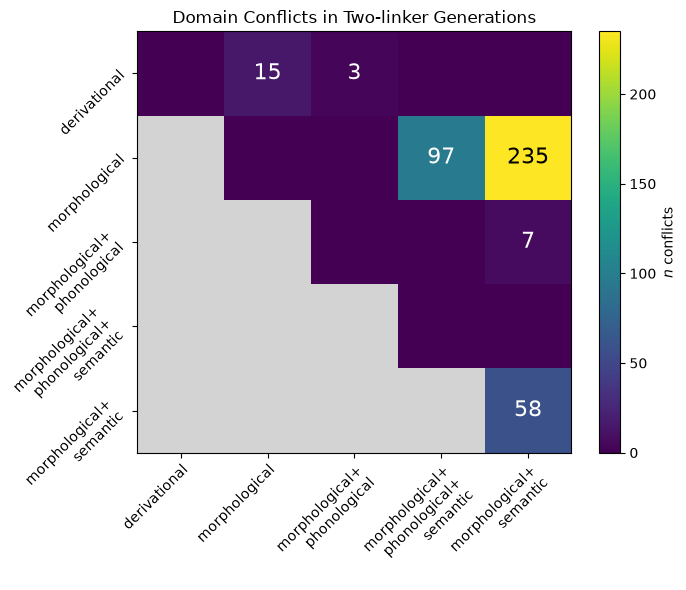

In [22]:
unique_domain_sets = set()
domain_confls_data = defaultdict(lambda: defaultdict(int))
for acceptable_linkers in acceptable_linkers_all.values():
    if len(acceptable_linkers) != 2 or acceptable_linkers.get("_", []) == [DEF_ID]:
        continue
    domains = defaultdict(set)
    keys = list(acceptable_linkers.keys())
    for i in range(len(keys)):
        for c_id in acceptable_linkers[keys[i]]:
            if c_id == DEF_ID:
                continue
            for domain in constraints[c_id]["domain_type"]:
                domains[i].add(domain)
        domains[i] = "+\n".join(sorted(domains[i]))
    domain_confl = sorted(domains.values())
    unique_domain_sets.update(domain_confl)
    domain_confls_data[domain_confl[0]][domain_confl[1]] += 1

domain_map = {
    domain_set: i for i, domain_set in enumerate(sorted(unique_domain_sets))
}
domain_confls_matrix = np.zeros((len(domain_map), len(domain_map)))

for ds1, conflicts in domain_confls_data.items():
    for ds2, n in conflicts.items():
        domain_confls_matrix[domain_map[ds1], domain_map[ds2]] = n

domain_confls_matrix

plt.figure(figsize=(7, 6))
# fade out the lower triangle to indicate symmetricity
# https://stackoverflow.com/a/2332520
lower_mask = np.tri(domain_confls_matrix.shape[0], k=-1)
domain_confls_matrix = np.ma.array(domain_confls_matrix, mask=lower_mask)
# https://matplotlib.org/stable/users/explain/colors/colormaps.html
cmap = plt.cm.viridis.copy()
# https://matplotlib.org/stable/gallery/color/named_colors.html
cmap.set_bad("lightgrey")  # grey where masked
plt.imshow(domain_confls_matrix, cmap=cmap, aspect="auto")
plt.colorbar(label="$n$ conflicts")
plt.title("Domain Conflicts in Two-linker Generations")
ticks, labels = list(domain_map.values()), list(domain_map.keys())
plt.xticks(ticks, labels=labels, fontsize=10, rotation=45, ha="right",rotation_mode="anchor")
plt.yticks(ticks, labels=labels, fontsize=10, rotation=45)

for i, j in product(range(len(domain_map)), repeat=2):
    val = domain_confls_matrix[i, j]
    if val > 0:
        plt.text(
            j, i, f"{int(val)}",
            ha="center", va="center",
            color="white" if val < 200 else "black",
            fontsize=16
        )

plt.tight_layout()
plt.savefig("out/domain_confls.png", dpi="figure")
plt.show()

## Compound Modeling: Intro

In [4]:
metrics_summary = load_tsv_generic("out/metrics_summary.tsv")
metrics_summary

,acc,f1
yang-cvg,0.715,0.446
yang-cond,0.713,0.397
albright-hayes,0.667,0.230
rand,0.375,0.128
zero,0.570,0.104


### Albright & Hayes 2002

* The three first best results include the 

In [5]:
method_dir = os.path.join(outdir, "albright-hayes")

In [6]:
# * Three worst results are with -l2p
# * Cooperation does not improve the scores
# * The low metrics are caused by vistually absent
# possibility to produce pluralic linkers due to
# the low regularity of the semantic constraints
metric_summary_ah02 = load_tsv_generic(os.path.join(method_dir, "metrics_summary.tsv"))
metric_summary_ah02

,acc,f1,is_best_key
+count_def|+coop|+l2p,0.667,0.230,True
+count_def|+coop|-l2p,0.667,0.230,False
+count_def|-coop|+l2p,0.667,0.230,False
-count_def|+coop|+l2p,0.667,0.230,False
-count_def|-coop|+l2p,0.667,0.230,False
-count_def|+coop|-l2p,0.667,0.223,False
+count_def|-coop|-l2p,0.660,0.221,False
-count_def|-coop|-l2p,0.660,0.221,False


In [7]:
ldistr_comparison = load_tsv_generic(os.path.join(method_dir, "ldistr_comparison.tsv"))
f1_acc_df = load_tsv_generic(os.path.join(method_dir, "f1_acc_df.tsv"))
cnf_matrix = load_tsv_generic(os.path.join(method_dir, "confusion_matrix.tsv"))

AH02 overproduces a zero linker and underproduces _-en-_ and _-"er-_. All the other linkers are never produced (except for _-s-_ which is produced a negligible number of times).

In [8]:
ldistr_comparison

,reference,ours
_,0.570,0.882
_+en_,0.186,0.090
_+=er_,0.160,0.027
_+e_,0.048,0.000
_+=e_,0.015,0.000
_+s_,0.015,0.001
_+=_,0.007,0.000


This consequently leads to a zero accuracy and F1 score over the four non-produced linkers, and a low recall (hence, F1 score) over the two underproduced linkers. While having a great recall for a zero linker, AH02 is not very precise over it. Overall, the low F1 score is explained by the underrepresentedness of most of the linkers and overfavoring the zero.

In [9]:
f1_acc_df

,acc,f1,N,prec,recall
avg,0.667,0.230,882.0,0.327,0.224
_,0.982,0.771,503.0,0.635,0.982
_+en_,0.476,0.642,164.0,0.987,0.476
_+=er_,0.113,0.194,141.0,0.667,0.113
_+e_,0.000,0.000,42.0,0.000,0.000
_+=e_,0.000,0.000,13.0,0.000,0.000
_+s_,0.000,0.000,13.0,0.000,0.000
_+=_,0.000,0.000,6.0,0.000,0.000


The overproduction of zero originates from the four non-produced linkers: they were all false predicted as zero.

In [10]:
cnf_matrix

,_,_+en_,_+=er_,_+e_,_+=e_,_+s_,_+=_
_,0.982,0.002,0.016,0.0,0.0,0.000,0.0
_+en_,0.518,0.476,0.000,0.0,0.0,0.006,0.0
_+=er_,0.887,0.000,0.113,0.0,0.0,0.000,0.0
_+e_,1.000,0.000,0.000,0.0,0.0,0.000,0.0
_+=e_,1.000,0.000,0.000,0.0,0.0,0.000,0.0
_+s_,1.000,0.000,0.000,0.0,0.0,0.000,0.0
_+=_,1.000,0.000,0.000,0.0,0.0,0.000,0.0


Correspondingly, the constraint(s) for the zero linker must always win the ones for _"0_, _-s-_, _-"e_, and _-e_. Let's investigate the constraint conflicts and their resolution under AH02 to understand why this is the case.

### Short Demonstration of `CompXConstraints`

##### 'Kinderwagen'

In [4]:
comp_gecodb = "kind_+er_wagen"
appl_row = appl_ind.loc[comp_gecodb]
cxc = CompXConstraints(appl_row)
cxc.true

'_+=er_'

In [5]:
cxc.acceptable_linkers

defaultdict(list,
            {'_': ['def-0',
              'p2l:decl_cl:pl:#er-0/er|def-0/er',
              'p2l:decl_cl:pl:#er-0/er|!pl_interpr-0'],
             '_+=er_': ['p2l:decl_cl:pl:#er-0/er|def-0/er',
              'p2l:decl_cl:pl:#er-0/er|anim-er']})

In [6]:
cxc.unacceptable_linkers

defaultdict(list,
            {'_+s_': ['l2p:s|tend_cmpx_morph', 'l2p:s|tend_cmpx_phon'],
             '_+en_': ['l2p:en|par'],
             '_+e_': ['l2p:e|par'],
             '_+=e_': ['l2p:e_uml'],
             '_+=_': ['l2p:0_uml']})

In [7]:
cxc.predict(
    method="albright_hayes",
    count_def_constr=False,
    constr_cooperation=False,
    restrict_with_l2p=False
)

cxc.gen_constr_df

,linker,condition,spec_score,cvg,reg,confidence
c_id,,,,,,
p2l:decl_cl:pl:#er-0/er|!pl_interpr-0,_,[PL:er] & [sem:!PL],25.2,0.171,0.622,0.6220
p2l:decl_cl:pl:#er-0/er|anim-er,_+=er_,[PL:er] & [[sem:anim] | [sem:pers]],28.0,0.003,0.501,0.5010
p2l:decl_cl:pl:#er-0/er|def-0/er,_,[PL:er],14.0,0.021,0.815,0.4075
p2l:decl_cl:pl:#er-0/er|def-0/er,_+=er_,[PL:er],14.0,0.021,0.815,0.4075


In [8]:
cxc.linker_scoreboard

,confidence,cvg,c_id
linker,,,
_,0.622,0.171,p2l:decl_cl:pl:#er-0/er|!pl_interpr-0
_+=er_,0.501,0.003,p2l:decl_cl:pl:#er-0/er|anim-er


In [9]:
cxc.y_pred

'_'

In [10]:
cxc.predict(
    method="albright_hayes",
    count_def_constr=True,
    constr_cooperation=True,
    restrict_with_l2p=False
)
 
cxc.linker_scoreboard

,confidence,cvg,c_id
linker,,,
_,1.0295,0.192,"p2l:decl_cl:pl:#er-0/er|def-0/er, p2l:decl_cl:..."
_+=er_,0.9085,0.024,"p2l:decl_cl:pl:#er-0/er|def-0/er, p2l:decl_cl:..."


##### 'Geschenkeliste'

In [11]:
comp_gecodb = "geschenk_+e_liste"
appl_row = appl_ind.loc[comp_gecodb]
cxc = CompXConstraints(appl_row)
cxc.true

'_+e_'

In [12]:
cxc.predict(
    method="albright_hayes",
    count_def_constr=True,
    constr_cooperation=False,
    restrict_with_l2p=True
)

cxc.restr_constr_df

,linker,condition,spec_score,cvg,reg,confidence
c_id,,,,,,
l2p:er|par,_+=er_,[PL:er],14.0,0.009,1.000,1.000
l2p:e_uml,_+=e_,[PL:ue],14.0,0.003,1.000,1.000
l2p:0_uml,_+=_,[PL:uo],14.0,0.001,1.000,1.000
l2p:en|par,_+en_,[PL:en],14.0,0.152,0.985,0.985
l2p:es|mono_syl,_+es_,[nsyl:mono] | [[nsyl:mono] & [drv:PRX]],20.4,0.010,0.972,0.972
l2p:er|smpx,_+=er_,[drv:smpx],14.0,0.009,0.903,0.903
l2p:e|smpx,_+e_,[drv:smpx],14.0,0.009,0.806,0.806


In [13]:
cxc.linker_scoreboard

,confidence,cvg,c_id,removed_by
linker,,,,
_,0.754,0.162,p2l:decl_cl:pl:#e-0|def-0,
_+s_,0.649,0.159,p2l:drv:prx_deverb-s,
_+e_,0.544,0.079,p2l:decl_cl:pl:#e-0|pl_interpr-e,l2p:e|smpx


In [14]:
cxc.predict(
    method="albright_hayes",
    count_def_constr=False,
    constr_cooperation=True,
    restrict_with_l2p=True
)

cxc.linker_scoreboard

,confidence,cvg,c_id,removed_by
linker,,,,
_,0.754,0.162,p2l:decl_cl:pl:#e-0|def-0,
_+s_,0.649,0.159,p2l:drv:prx_deverb-s,
_+e_,0.544,0.079,p2l:decl_cl:pl:#e-0|pl_interpr-e,l2p:e|smpx


In [15]:
cxc.predict(
    method="yang-cond",
    count_def_constr=True,
    constr_cooperation=False,
    restrict_with_l2p=True
)

cxc.linker_scoreboard

,confidence,cvg,c_id,removed_by
linker,,,,
_+e_,26.8,0.079,p2l:decl_cl:pl:#e-0|pl_interpr-e,
_,14.0,0.162,p2l:decl_cl:pl:#e-0|def-0,
_+s_,12.7,0.159,p2l:drv:prx_deverb-s,


In [16]:
cxc.predict(
    method="yang-cvg",
    count_def_constr=True,
    constr_cooperation=False,
    restrict_with_l2p=True
)

cxc.linker_scoreboard

,confidence,reg,c_id,removed_by
linker,,,,
_+e_,0.079,0.544,p2l:decl_cl:pl:#e-0|pl_interpr-e,
_+s_,0.159,0.649,p2l:drv:prx_deverb-s,
_,0.162,0.754,p2l:decl_cl:pl:#e-0|def-0,


### Prerequisites

In [38]:
ldistr_comparison, accuracies_df, f1_df, cnf_matrix = ah02_metrics["+count_def|+coop|+l2p"]

In [39]:
ldistr_comparison

,reference,ours
_,0.570,0.882
_+en_,0.186,0.090
_+=er_,0.160,0.027
_+e_,0.048,0.000
_+=e_,0.015,0.000
_+s_,0.015,0.001
_+=_,0.007,0.000


In [40]:
cnf_matrix

,_,_+en_,_+=er_,_+e_,_+=e_,_+s_,_+=_
_,0.982,0.002,0.016,0.0,0.0,0.000,0.0
_+en_,0.518,0.476,0.000,0.0,0.0,0.006,0.0
_+=er_,0.887,0.000,0.113,0.0,0.0,0.000,0.0
_+e_,1.000,0.000,0.000,0.0,0.0,0.000,0.0
_+=e_,1.000,0.000,0.000,0.0,0.0,0.000,0.0
_+s_,1.000,0.000,0.000,0.0,0.0,0.000,0.0
_+=_,1.000,0.000,0.000,0.0,0.0,0.000,0.0


In [49]:
for (key_1, preds_1), (key_2, preds_2) in pairwise(Y_pred_ah02.items()):
    print(key_1, "\t", key_2)
    print(round(accuracy_score(preds_1, preds_2), 3))
    print()

+count_def|+coop|+l2p 	 +count_def|+coop|-l2p
1.0

+count_def|+coop|-l2p 	 +count_def|-coop|+l2p
1.0

+count_def|-coop|+l2p 	 +count_def|-coop|-l2p
0.965

+count_def|-coop|-l2p 	 -count_def|+coop|+l2p
0.965

-count_def|+coop|+l2p 	 -count_def|+coop|-l2p
0.972

-count_def|+coop|-l2p 	 -count_def|-coop|+l2p
0.972

-count_def|-coop|+l2p 	 -count_def|-coop|-l2p
0.965



In [50]:
Y_pred_y16_cond = {}
y16_cond_metrics = {}
s = lambda x: "+" if x else "-"
for count_def, coop, l2p in product([True, False], repeat=3):
    key = (
        f"{s(count_def)}count_def|"
        f"{s(coop)}coop|"
        f"{s(l2p)}l2p"
    )
    Y_pred_y16_cond[key] = [
        cxc.predict(
            method="yang-cond",
            count_def_constr=count_def,
            constr_cooperation=coop,
            restrict_with_l2p=l2p
        )
        for cxc in tqdm(cXc)
    ]
    y16_cond_metrics[key] = calculate_metrics(Y_pred_y16_cond[key])

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

In [ ]:
# * All the results are identical
# * L2P cannot restrict anything because their
# conditions are always quite general
metrics_y16_cond_df = pd.DataFrame({
    key: {
        "acc": metrics[1].loc["overall"],
        "acc_balanced": metrics[1].loc["balanced"],
        "f1_avg": metrics[2].loc["avg", "f1"]
    }
    for key, metrics in y16_cond_metrics.items()
}).T.sort_values(by=["f1_avg", "acc_balanced", "acc"], ascending=False)

metrics_y16_cond_df

,acc,acc_balanced,f1_avg
+count_def|+coop|+l2p,0.713,0.361,0.397
+count_def|+coop|-l2p,0.713,0.361,0.397
+count_def|-coop|+l2p,0.713,0.361,0.397
+count_def|-coop|-l2p,0.713,0.361,0.397
-count_def|+coop|+l2p,0.713,0.361,0.397
-count_def|+coop|-l2p,0.713,0.361,0.397
-count_def|-coop|+l2p,0.713,0.361,0.397
-count_def|-coop|-l2p,0.713,0.361,0.397


In [52]:
for (key_1, preds_1), (key_2, preds_2) in pairwise(Y_pred_y16_cond.items()):
    print(key_1, "\t", key_2)
    print(round(accuracy_score(preds_1, preds_2), 3))
    print()

+count_def|+coop|+l2p 	 +count_def|+coop|-l2p
1.0

+count_def|+coop|-l2p 	 +count_def|-coop|+l2p
0.999

+count_def|-coop|+l2p 	 +count_def|-coop|-l2p
1.0

+count_def|-coop|-l2p 	 -count_def|+coop|+l2p
0.999

-count_def|+coop|+l2p 	 -count_def|+coop|-l2p
1.0

-count_def|+coop|-l2p 	 -count_def|-coop|+l2p
0.999

-count_def|-coop|+l2p 	 -count_def|-coop|-l2p
1.0



In [53]:
ldistr_comparison, accuracies_df, f1_df, cnf_matrix = y16_cond_metrics["+count_def|+coop|+l2p"]

In [54]:
ldistr_comparison

,reference,ours
_,0.570,0.748
_+en_,0.186,0.125
_+=er_,0.160,0.101
_+e_,0.048,0.010
_+=e_,0.015,0.007
_+s_,0.015,0.001
_+=_,0.007,0.008


In [55]:
f1_df

,prec,recall,f1,N
avg,0.502,0.361,0.397,126.0
_,0.717,0.940,0.813,503.0
_+en_,0.709,0.476,0.569,164.0
_+=er_,0.775,0.489,0.600,141.0
_+e_,0.333,0.071,0.118,42.0
_+=e_,0.833,0.385,0.526,13.0
_+s_,0.000,0.000,0.000,13.0
_+=_,0.143,0.167,0.154,6.0


In [56]:
cnf_matrix

,_,_+en_,_+=er_,_+e_,_+=e_,_+s_,_+=_
_,0.940,0.014,0.020,0.012,0.002,0.000,0.012
_+en_,0.518,0.476,0.000,0.000,0.000,0.006,0.000
_+=er_,0.511,0.000,0.489,0.000,0.000,0.000,0.000
_+e_,0.381,0.548,0.000,0.071,0.000,0.000,0.000
_+=e_,0.615,0.000,0.000,0.000,0.385,0.000,0.000
_+s_,0.077,0.154,0.769,0.000,0.000,0.000,0.000
_+=_,0.833,0.000,0.000,0.000,0.000,0.000,0.167


In [65]:
Y_pred_y16_cvg = {}
y16_cvg_metrics = {}
s = lambda x: "+" if x else "-"
for count_def, coop, l2p in product([True, False], repeat=3):
    key = (
        f"{s(count_def)}count_def|"
        f"{s(coop)}coop|"
        f"{s(l2p)}l2p"
    )
    Y_pred_y16_cvg[key] = [
        cxc.predict(
            method="yang-cvg",
            count_def_constr=count_def,
            constr_cooperation=coop,
            restrict_with_l2p=l2p
        )
        for cxc in tqdm(cXc)
    ]
    y16_cvg_metrics[key] = calculate_metrics(Y_pred_y16_cvg[key])

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

  0%|          | 0/882 [00:00<?, ?it/s]

In [ ]:
# * All four runs with -L2P have the worst results:
# combined with a similar result from AH02, we conclude
# that L2P do play a role
# * Removing cooperation produces better results:
# combined with a similar result from AH02, we conclude
# that compounding constraints do not cooperate
# * On the other hand, relying on cvg only produces too many
# "rare" linkers where they shouldn't be
metrics_y16_cvg_df = pd.DataFrame({
    key: {
        "acc": metrics[1].loc["overall"],
        "acc_balanced": metrics[1].loc["balanced"],
        "f1_avg": metrics[2].loc["avg", "f1"]
    }
    for key, metrics in y16_cvg_metrics.items()
}).T.sort_values(by=["f1_avg", "acc_balanced", "acc"], ascending=False)

metrics_y16_cvg_df

,acc,acc_balanced,f1_avg
+count_def|-coop|+l2p,0.715,0.395,0.446
-count_def|-coop|+l2p,0.715,0.395,0.446
+count_def|+coop|+l2p,0.590,0.421,0.433
-count_def|+coop|+l2p,0.590,0.421,0.433
+count_def|-coop|-l2p,0.689,0.316,0.357
-count_def|-coop|-l2p,0.689,0.316,0.357
+count_def|+coop|-l2p,0.563,0.343,0.343
-count_def|+coop|-l2p,0.563,0.343,0.343


In [67]:
for (key_1, preds_1), (key_2, preds_2) in pairwise(Y_pred_y16_cvg.items()):
    print(key_1, "\t", key_2)
    print(round(accuracy_score(preds_1, preds_2), 3))
    print()

+count_def|+coop|+l2p 	 +count_def|+coop|-l2p
0.965

+count_def|+coop|-l2p 	 +count_def|-coop|+l2p
0.618

+count_def|-coop|+l2p 	 +count_def|-coop|-l2p
0.965

+count_def|-coop|-l2p 	 -count_def|+coop|+l2p
0.618

-count_def|+coop|+l2p 	 -count_def|+coop|-l2p
0.965

-count_def|+coop|-l2p 	 -count_def|-coop|+l2p
0.618

-count_def|-coop|+l2p 	 -count_def|-coop|-l2p
0.965



In [68]:
ldistr_comparison, accuracies_df, f1_df, cnf_matrix = y16_cvg_metrics["+count_def|+coop|+l2p"]

In [69]:
ldistr_comparison

,reference,ours
_,0.570,0.460
_+en_,0.186,0.104
_+=er_,0.160,0.370
_+e_,0.048,0.039
_+=e_,0.015,0.007
_+s_,0.015,0.020
_+=_,0.007,0.000


In [70]:
f1_df

,prec,recall,f1,N
avg,0.518,0.421,0.433,126.0
_,0.692,0.559,0.618,503.0
_+en_,0.967,0.543,0.695,164.0
_+=er_,0.365,0.844,0.510,141.0
_+e_,0.765,0.619,0.684,42.0
_+=e_,0.833,0.385,0.526,13.0
_+s_,0.000,0.000,0.000,13.0
_+=_,0.000,0.000,0.000,6.0


In [71]:
cnf_matrix

,_,_+en_,_+=er_,_+e_,_+=e_,_+s_,_+=_
_,0.559,0.006,0.392,0.012,0.002,0.030,0.0
_+en_,0.457,0.543,0.000,0.000,0.000,0.000,0.0
_+=er_,0.156,0.000,0.844,0.000,0.000,0.000,0.0
_+e_,0.310,0.000,0.000,0.619,0.000,0.071,0.0
_+=e_,0.615,0.000,0.000,0.000,0.385,0.000,0.0
_+s_,0.077,0.000,0.769,0.154,0.000,0.000,0.0
_+=_,1.000,0.000,0.000,0.000,0.000,0.000,0.0
